In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

import pandas as pd

url = "https://raw.githubusercontent.com/reisanar/datasets/master/Heart.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset shape: (303, 15)


,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


['Unnamed: 0', 'Age', 'Sex', 'ChestPain', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'AHD']


In [7]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()


Missing values in each column:
Unnamed: 0    0
Age           0
Sex           0
ChestPain     0
RestBP        0
Chol          0
Fbs           0
RestECG       0
MaxHR         0
ExAng         0
Oldpeak       0
Slope         0
Ca            4
Thal          2
AHD           0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   Age         303 non-null    int64  
 2   Sex         303 non-null    int64  
 3   ChestPain   303 non-null    object 
 4   RestBP      303 non-null    int64  
 5   Chol        303 non-null    int64  
 6   Fbs         303 non-null    int64  
 7   RestECG     303 non-null    int64  
 8   MaxHR       303 non-null    int64  
 9   ExAng       303 non-null    int64  
 10  Oldpeak     303 non-null    float64
 11  Slope       303 non-null    int64  
 12  Ca        

In [8]:

print("Unique index values:", df["Unnamed: 0"].nunique())
print("First five index values:", df["Unnamed: 0"].head().tolist())


Unique index values: 303
First five index values: [1, 2, 3, 4, 5]


In [9]:

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values before cleaning:
Unnamed: 0    0
Age           0
Sex           0
ChestPain     0
RestBP        0
Chol          0
Fbs           0
RestECG       0
MaxHR         0
ExAng         0
Oldpeak       0
Slope         0
Ca            4
Thal          2
AHD           0
dtype: int64

Total missing values: 6


In [10]:

df = df.drop(columns=["Unnamed: 0"])

print("Updated dataset shape:", df.shape)
print(df.head())


Updated dataset shape: (303, 14)
   Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63    1       typical     145   233    1        2    150      0      2.3   
1   67    1  asymptomatic     160   286    0        2    108      1      1.5   
2   67    1  asymptomatic     120   229    0        2    129      1      2.6   
3   37    1    nonanginal     130   250    0        0    187      0      3.5   
4   41    0    nontypical     130   204    0        2    172      0      1.4   

   Slope   Ca        Thal  AHD  
0      3  0.0       fixed   No  
1      2  3.0      normal  Yes  
2      2  2.0  reversable  Yes  
3      3  0.0      normal   No  
4      1  0.0      normal   No  


In [11]:

print(df["AHD"].value_counts())
print("\nTarget percentages:")
print(df["AHD"].value_counts(normalize=True) * 100)


AHD
No     164
Yes    139
Name: count, dtype: int64

Target percentages:
AHD
No     54.125413
Yes    45.874587
Name: proportion, dtype: float64


In [12]:

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Categorical columns: ['ChestPain', 'Thal', 'AHD']

ChestPain:
ChestPain
asymptomatic    144
nonanginal       86
nontypical       50
typical          23
Name: count, dtype: int64

Thal:
Thal
normal        166
reversable    117
fixed          18
NaN             2
Name: count, dtype: int64

AHD:
AHD
No     164
Yes    139
Name: count, dtype: int64


In [13]:

# Input features: everything except the target
X = df.drop(columns=["AHD"])

# Target: what we want to predict
y = df["AHD"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget examples:")
print(y.head())


Features shape: (303, 13)
Target shape: (303,)

Feature columns:
['Age', 'Sex', 'ChestPain', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca', 'Thal']

Target examples:
0     No
1    Yes
2    Yes
3     No
4     No
Name: AHD, dtype: object


In [14]:

categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_columns)
print("\nNumerical features:", numerical_columns)


Categorical features: ['ChestPain', 'Thal']

Numerical features: ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca']


In [15]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training features: (242, 13)
Testing features: (61, 13)
Training targets: (242,)
Testing targets: (61,)


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify column types using the training data
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Process numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct processing to each column type
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created successfully!")
print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)


Preprocessing pipeline created successfully!
Numerical columns: ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca']
Categorical columns: ['ChestPain', 'Thal']


In [17]:

from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Fit preprocessing and the model on training data only
model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [18]:

y_pred = model.predict(X_test)

print("Actual outcomes:")
print(y_test.head(10).tolist())

print("\nPredicted outcomes:")
print(y_pred[:10].tolist())


Actual outcomes:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']

Predicted outcomes:
['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("Logistic Regression Results")
print("----------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Logistic Regression Results
----------------------------
Accuracy:  0.9016
Precision: 0.8667
Recall:    0.9286
F1-score:  0.8966

Classification Report:
              precision    recall  f1-score   support

          No       0.94      0.88      0.91        33
         Yes       0.87      0.93      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61



In [20]:

import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
)

display(cm_df)


,Predicted No,Predicted Yes
Actual No,29,4
Actual Yes,2,26


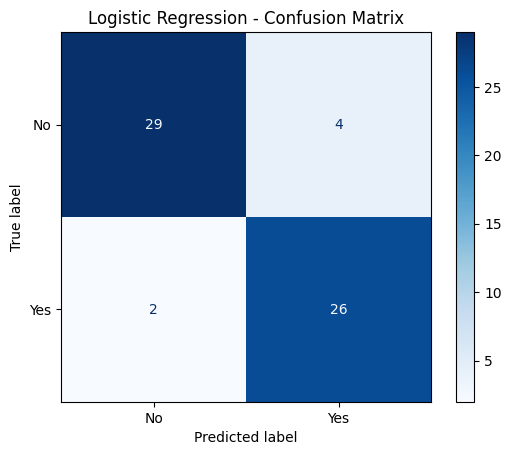

In [21]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [22]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


In [23]:

y_pred_tree = decision_tree_model.predict(X_test)

print("Actual outcomes:")
print(y_test.head(10).tolist())

print("\nDecision Tree predictions:")
print(y_pred_tree[:10].tolist())


Actual outcomes:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']

Decision Tree predictions:
['Yes', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No']


In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(
    y_test, y_pred_tree, pos_label="Yes", zero_division=0
)
tree_recall = recall_score(
    y_test, y_pred_tree, pos_label="Yes", zero_division=0
)
tree_f1 = f1_score(
    y_test, y_pred_tree, pos_label="Yes", zero_division=0
)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy:  {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall:    {tree_recall:.4f}")
print(f"F1-score:  {tree_f1:.4f}")


Decision Tree Results
---------------------
Accuracy:  0.7377
Precision: 0.7143
Recall:    0.7143
F1-score:  0.7143


In [25]:

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [26]:

y_pred_rf = random_forest_model.predict(X_test)

print("Actual outcomes:")
print(y_test.head(10).tolist())

print("\nRandom Forest predictions:")
print(y_pred_rf[:10].tolist())


Actual outcomes:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']

Random Forest predictions:
['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']


In [27]:

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")


Random Forest Results
---------------------
Accuracy:  0.8689
Precision: 0.8125
Recall:    0.9286
F1-score:  0.8667


In [28]:

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy, tree_accuracy, rf_accuracy
    ],
    "Precision": [
        precision, tree_precision, rf_precision
    ],
    "Recall": [
        recall, tree_recall, rf_recall
    ],
    "F1-score": [
        f1, tree_f1, rf_f1
    ]
})

display(
    results.sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.901639,0.866667,0.928571,0.896552
1,Random Forest,0.868852,0.812500,0.928571,0.866667
2,Decision Tree,0.737705,0.714286,0.714286,0.714286


In [29]:

import joblib

# Save the best-performing pipeline
joblib.dump(model, "disease_prediction_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [31]:

import os

file_path = "disease_prediction_model.pkl"

if os.path.exists(file_path):
    print("File exists!")
    print("File size:", os.path.getsize(file_path), "bytes")
else:
    print("Model file not found!")


File exists!
File size: 5178 bytes


In [32]:

loaded_model = joblib.load("disease_prediction_model.pkl")

test_predictions = loaded_model.predict(X_test.iloc[:5])

print("Loaded model successfully!")
print("Predictions:", test_predictions)


Loaded model successfully!
Predictions: ['No' 'Yes' 'No' 'No' 'No']


In [30]:

from google.colab import files

files.download("disease_prediction_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>